# Human Activity Recognition: Feature Extraction

This notebook derives time-domain and frequency-domain features from the combined accelerometer and gyroscope dataset. It uses **2-second windows** with a **1-second hop** and calculates statistical, magnitude-based, correlation, and FFT-derived features.

Z-score normalization is fitted using **training windows only**. The same training means and scales are then applied to the held-out test windows to prevent information leakage.

## Input Data

The notebook searches common project locations for the combined sensor CSV. If it is not found in Google Colab, the notebook prompts for the combined sensor CSV file. The input must include activity labels, recording IDs, train/test split labels, elapsed time, and the six accelerometer/gyroscope axes.


In [1]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REQUIRED_COLUMNS = {
    "recording_id", "activity", "split", "time_from_start_s",
    "acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"
}


def find_combined_csv():
    """Find the combined CSV in common notebook/project locations."""
    direct_candidates = [
        Path.cwd() / "data" / "processed" / "combined_sensor_data.csv",
        Path.cwd() / "HMM_Combined_Sensor_Data.csv",
        Path.cwd() / "combined_sensor_data.csv",
        Path("/content/data/processed/combined_sensor_data.csv"),
        Path("/content/HMM_Combined_Sensor_Data.csv"),
        Path("/content/combined_sensor_data.csv"),
        Path("/mnt/data/HMM_Combined_Sensor_Data.csv"),
    ]
    for p in direct_candidates:
        if p.is_file():
            return p

    # Search common notebook folders for the full project layout or a renamed CSV.
    search_roots = []
    for p in [Path.cwd(), Path("/content"), Path("/mnt/data")]:
        if p.exists() and p not in search_roots:
            search_roots.append(p)
    for root in search_roots:
        try:
            for p in root.glob("**/data/processed/combined_sensor_data.csv"):
                return p
            for name in ("HMM_Combined_Sensor_Data.csv", "combined_sensor_data.csv"):
                for p in root.glob(f"**/{name}"):
                    return p
        except (PermissionError, OSError):
            pass

    # In Google Colab, offer an upload prompt if the file is not found.
    try:
        from google.colab import files
        print("Combined sensor data was not found automatically. Upload the combined sensor CSV when prompted.")
        uploaded = files.upload()
        for name in uploaded:
            if name.lower().endswith(".csv"):
                p = Path("/content") / name
                if p.is_file():
                    return p
    except ImportError:
        pass

    raise FileNotFoundError(
        "Combined sensor CSV not found. Upload the combined sensor CSV to the notebook session, "
        "or extract the complete project ZIP archive first."
    )

INPUT_CSV = find_combined_csv()

# When the input CSV belongs to the full repository, use that repository as
# the output root. This keeps Notebook 2 connected to Notebook 3.
PROJECT_ROOT = None
for candidate in [Path(INPUT_CSV).parent, *Path(INPUT_CSV).parents]:
    if (candidate / "scripts" / "preprocess.py").is_file() and (candidate / "data" / "processed").is_dir():
        PROJECT_ROOT = candidate
        break

combined = pd.read_csv(INPUT_CSV)
missing = REQUIRED_COLUMNS - set(combined.columns)
if missing:
    raise ValueError(
        f"The selected file is not the expected combined sensor CSV. Missing columns: {sorted(missing)}. "
        "Upload the combined sensor CSV."
    )

print("Input CSV:", INPUT_CSV)
print("Rows:", f"{len(combined):,}")
print("Recordings:", combined["recording_id"].nunique())
print("Activities:", sorted(combined["activity"].dropna().unique()))
display(combined.head())

Combined sensor data was not found automatically. Upload the combined sensor CSV when prompted.


Saving HMM_Combined_Sensor_Data.csv to HMM_Combined_Sensor_Data.csv
Input CSV: /content/HMM_Combined_Sensor_Data.csv
Rows: 18,594
Recordings: 52
Activities: ['jumping', 'standing', 'still', 'walking']


,recording_id,activity,split,sample_index,timestamp_ns,seconds_elapsed,time_from_start_s,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
0,jumping_01,jumping,train,0,1793028264455335000,0.089335,0.000000,-0.453063,0.268308,-0.009483,0.608661,0.196290,0.030390
1,jumping_01,jumping,train,1,1793028264475387000,0.109387,0.020052,-0.392619,0.383869,-0.482359,0.693698,0.344590,0.120402
2,jumping_01,jumping,train,2,1793028264495437800,0.129438,0.040103,-0.413266,0.477620,-0.322306,0.875810,0.356110,0.186510
3,jumping_01,jumping,train,3,1793028264515489800,0.149490,0.060155,-0.393194,0.582394,-0.110532,1.031206,0.321011,0.182858
4,jumping_01,jumping,train,4,1793028264535540700,0.169541,0.080206,-0.574535,-0.025278,1.312708,0.707700,-0.022423,0.063923


## Feature Extraction Method

At approximately 50 Hz, each 2-second window contains about 100 sensor samples. Features include axis means, standard deviations, variances and RMS values; accelerometer and gyroscope magnitude statistics; signal magnitude area; inter-axis correlations; dominant FFT frequency; and spectral energy.


In [2]:
# Feature extraction settings
ACTIVITIES = ["standing", "walking", "jumping", "still"]
SENSOR_AXES = ["acc_x", "acc_y", "acc_z", "gyro_x", "gyro_y", "gyro_z"]
WINDOW_SECONDS = 2.0
HOP_SECONDS = 1.0


def safe_corr(a, b):
    if len(a) < 2 or np.std(a) < 1e-12 or np.std(b) < 1e-12:
        return 0.0
    value = float(np.corrcoef(a, b)[0, 1])
    return value if np.isfinite(value) else 0.0


def dominant_frequency_and_energy(x, fs):
    """Dominant non-DC FFT frequency and normalized spectral energy."""
    x = np.asarray(x, dtype=float)
    x = x - np.mean(x)
    n = len(x)
    if n < 4 or fs <= 0:
        return 0.0, 0.0
    spectrum = np.fft.rfft(x)
    freqs = np.fft.rfftfreq(n, d=1.0 / fs)
    amplitude = np.abs(spectrum)
    eligible = freqs >= 0.25
    if not eligible.any():
        dominant = 0.0
    else:
        eligible_indices = np.flatnonzero(eligible)
        dominant = float(freqs[eligible_indices[np.argmax(amplitude[eligible_indices])]])
    energy = float(np.sum(np.abs(spectrum[1:]) ** 2) / (n ** 2))
    return dominant, energy


def features_for_window(g, fs):
    f = {}
    arrays = {c: g[c].to_numpy(dtype=float) for c in SENSOR_AXES}
    for axis, x in arrays.items():
        f[f"{axis}_mean"] = float(np.mean(x))
        f[f"{axis}_std"] = float(np.std(x, ddof=1)) if len(x) > 1 else 0.0
        f[f"{axis}_variance"] = float(np.var(x, ddof=1)) if len(x) > 1 else 0.0
        f[f"{axis}_rms"] = float(np.sqrt(np.mean(x ** 2)))

    acc = np.column_stack([arrays[f"acc_{a}"] for a in "xyz"])
    gyro = np.column_stack([arrays[f"gyro_{a}"] for a in "xyz"])
    acc_mag = np.sqrt(np.sum(acc ** 2, axis=1))
    gyro_mag = np.sqrt(np.sum(gyro ** 2, axis=1))
    for name, mag in [("acc_mag", acc_mag), ("gyro_mag", gyro_mag)]:
        f[f"{name}_mean"] = float(np.mean(mag))
        f[f"{name}_std"] = float(np.std(mag, ddof=1)) if len(mag) > 1 else 0.0
        f[f"{name}_rms"] = float(np.sqrt(np.mean(mag ** 2)))
        dom, energy = dominant_frequency_and_energy(mag, fs)
        f[f"{name}_dominant_frequency_hz"] = dom
        f[f"{name}_spectral_energy"] = energy

    f["acc_signal_magnitude_area"] = float(np.mean(np.sum(np.abs(acc), axis=1)))
    f["gyro_signal_magnitude_area"] = float(np.mean(np.sum(np.abs(gyro), axis=1)))
    for prefix, sensor in [("acc", acc), ("gyro", gyro)]:
        for i, j, pair in [(0, 1, "xy"), (0, 2, "xz"), (1, 2, "yz")]:
            f[f"{prefix}_corr_{pair}"] = safe_corr(sensor[:, i], sensor[:, j])
    return f


def extract_window_features(data, window_seconds=WINDOW_SECONDS, hop_seconds=HOP_SECONDS):
    rows = []
    for recording_id, g0 in data.groupby("recording_id", sort=True):
        g = g0.sort_values("time_from_start_s").reset_index(drop=True)
        activity = str(g["activity"].iloc[0])
        split = str(g["split"].iloc[0])
        t = pd.to_numeric(g["time_from_start_s"], errors="coerce").to_numpy(dtype=float)
        dt = np.diff(t)
        dt = dt[np.isfinite(dt) & (dt > 0)]
        if len(dt) == 0:
            continue
        fs = float(1.0 / np.median(dt))
        last_t = float(np.max(t))
        start = 0.0
        window_index = 0
        min_samples = max(4, int(fs * window_seconds * 0.80))
        while start + window_seconds <= last_t + (1.0 / fs):
            mask = (t >= start) & (t < start + window_seconds)
            gw = g.loc[mask]
            tw = t[mask]
            if len(gw) >= min_samples and len(tw) > 1 and (tw.max() - tw.min()) >= window_seconds * 0.75:
                row = {
                    "recording_id": recording_id,
                    "activity": activity,
                    "split": split,
                    "window_index": window_index,
                    "window_start_s": float(start),
                    "window_end_s": float(start + window_seconds),
                    "window_samples": int(len(gw)),
                    "estimated_sampling_rate_hz": fs,
                }
                row.update(features_for_window(gw, fs))
                rows.append(row)
                window_index += 1
            start += hop_seconds

    result = pd.DataFrame(rows)
    if result.empty:
        raise ValueError("No feature windows were extracted. Check the input file and timestamps.")
    numeric = result.select_dtypes(include=[np.number]).columns
    if not np.isfinite(result[numeric].to_numpy(dtype=float)).all():
        raise ValueError("Feature extraction generated non-finite values.")
    return result

features = extract_window_features(combined)
metadata_cols = ["recording_id", "activity", "split", "window_index", "window_start_s", "window_end_s", "window_samples", "estimated_sampling_rate_hz"]
feature_columns = [c for c in features.columns if c not in metadata_cols]

train_mask = features["split"].eq("train")
if not train_mask.any():
    raise ValueError("No rows labeled split='train' were found; the CSV must include the train/test split from preprocessing.")
train_means = features.loc[train_mask, feature_columns].mean()
train_scales = features.loc[train_mask, feature_columns].std(ddof=0).replace(0, 1.0)
scaled = features[[c for c in features.columns if c not in feature_columns]].copy()
for c in feature_columns:
    scaled[c] = (features[c] - train_means[c]) / train_scales[c]
scaler = pd.DataFrame({"feature": feature_columns, "training_mean": train_means.values, "training_std_used": train_scales.values})

summary = features.groupby(["activity", "split"], as_index=False).agg(
    windows=("window_index", "size"),
    recordings=("recording_id", "nunique"),
    median_window_samples=("window_samples", "median"),
    median_sampling_rate_hz=("estimated_sampling_rate_hz", "median"),
)

print(f"Extracted {len(features):,} windows with {len(feature_columns)} numeric features each.")
print(f"Training windows: {(features['split'] == 'train').sum():,}")
print(f"Unseen test windows: {(features['split'] == 'test').sum():,}")
display(summary)

Extracted 292 windows with 42 numeric features each.
Training windows: 247
Unseen test windows: 45


,activity,split,windows,recordings,median_window_samples,median_sampling_rate_hz
0,jumping,test,13,2,100.0,49.872762
1,jumping,train,59,11,100.0,49.874583
2,standing,test,10,2,100.0,49.870332
3,standing,train,66,11,100.0,49.870332
4,still,test,11,2,100.0,49.870939
5,still,train,60,11,100.0,49.870939
6,walking,test,11,2,100.0,49.873367
7,walking,train,62,11,100.0,49.874583


## Normalize Features and Export Results

Feature scaling uses only the training split. The output includes the complete feature table, train/test subsets, normalized versions, saved scaling parameters, a summary table, and descriptive plots.


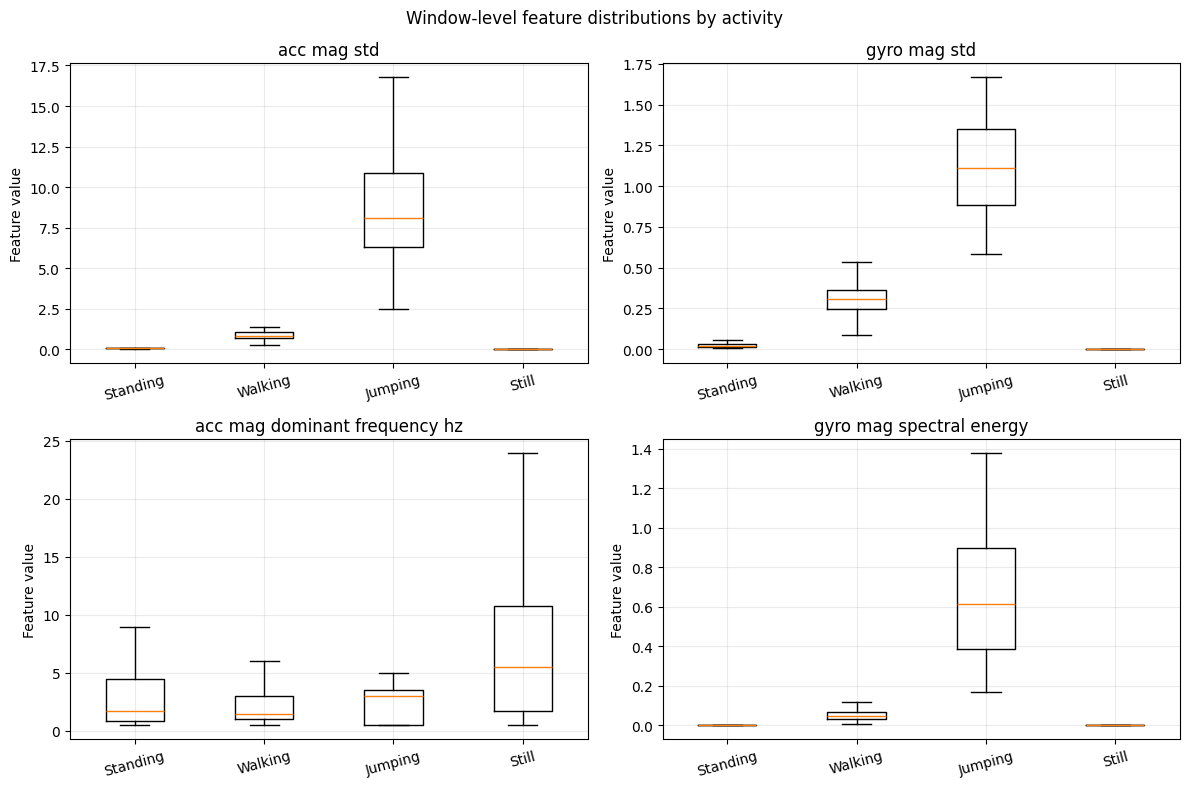

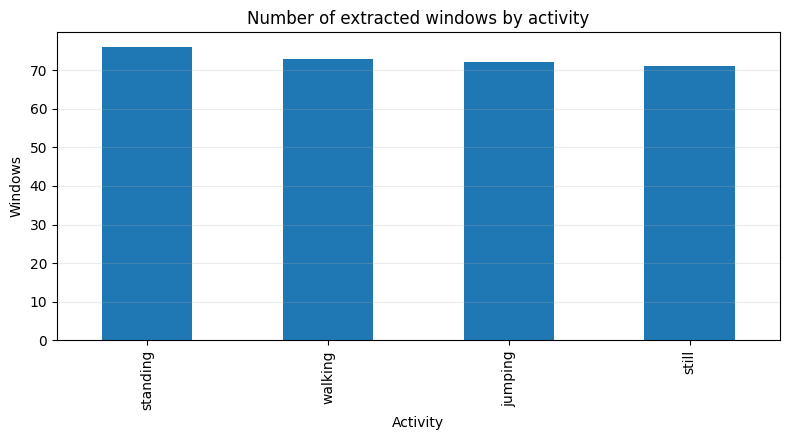

Input data: /content/HMM_Combined_Sensor_Data.csv
Raw feature table: /content/HMM_Feature_Extraction_Outputs/window_features.csv
Normalized feature table: /content/HMM_Feature_Extraction_Outputs/window_features_zscore.csv
Standalone feature export: /content/HMM_Feature_Extraction_Outputs/HMM_Window_Features.csv
Feature plots: /content/HMM_Feature_Extraction_Outputs


In [3]:
# Save feature tables and plots into the project folders.
# In the complete repository, Notebook 3 reads data/processed/window_features.csv.
if PROJECT_ROOT is not None:
    OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
    FIGURE_DIR = PROJECT_ROOT / "figures"
    FEATURE_EXPORT_DIR = PROJECT_ROOT / "data" / "features"
    FEATURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
else:
    # When only the combined CSV is uploaded, save everything in this output folder.
    OUTPUT_DIR = Path.cwd() / "HMM_Feature_Extraction_Outputs"
    FIGURE_DIR = OUTPUT_DIR
    FEATURE_EXPORT_DIR = OUTPUT_DIR

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Canonical files used by Notebook 3 and the command-line HMM script.
features.to_csv(OUTPUT_DIR / "window_features.csv", index=False)
scaled.to_csv(OUTPUT_DIR / "window_features_zscore.csv", index=False)
features.loc[features["split"].eq("train")].to_csv(OUTPUT_DIR / "train_window_features.csv", index=False)
features.loc[features["split"].eq("test")].to_csv(OUTPUT_DIR / "test_window_features.csv", index=False)
scaled.loc[scaled["split"].eq("train")].to_csv(OUTPUT_DIR / "train_window_features_zscore.csv", index=False)
scaled.loc[scaled["split"].eq("test")].to_csv(OUTPUT_DIR / "test_window_features_zscore.csv", index=False)
scaler.to_csv(OUTPUT_DIR / "feature_scaler_parameters.csv", index=False)
summary.to_csv(OUTPUT_DIR / "window_feature_summary.csv", index=False)

# Also save clearly named feature exports for standalone use and manual review.
features.to_csv(FEATURE_EXPORT_DIR / "HMM_Window_Features.csv", index=False)
scaled.to_csv(FEATURE_EXPORT_DIR / "HMM_Window_Features_ZScore.csv", index=False)

plot_cols = ["acc_mag_std", "gyro_mag_std", "acc_mag_dominant_frequency_hz", "gyro_mag_spectral_energy"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, plot_cols):
    data_by_activity = [features.loc[features.activity.eq(a), col].dropna().to_numpy() for a in ACTIVITIES]
    ax.boxplot(data_by_activity, showfliers=False)
    ax.set_xticks(range(1, len(ACTIVITIES) + 1), [a.capitalize() for a in ACTIVITIES])
    ax.set_title(col.replace("_", " "))
    ax.set_ylabel("Feature value")
    ax.tick_params(axis="x", rotation=15)
    ax.grid(True, alpha=0.25)
fig.suptitle("Window-level feature distributions by activity")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "window_feature_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

counts = features.groupby("activity")["window_index"].count().reindex(ACTIVITIES)
fig, ax = plt.subplots(figsize=(8, 4.5))
counts.plot(kind="bar", ax=ax)
ax.set_title("Number of extracted windows by activity")
ax.set_xlabel("Activity")
ax.set_ylabel("Windows")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "window_counts_by_activity.png", dpi=160, bbox_inches="tight")
plt.show()

print("Input data:", INPUT_CSV)
print("Raw feature table:", OUTPUT_DIR / "window_features.csv")
print("Normalized feature table:", OUTPUT_DIR / "window_features_zscore.csv")
print("Standalone feature export:", FEATURE_EXPORT_DIR / "HMM_Window_Features.csv")
print("Feature plots:", FIGURE_DIR)


## Output files

When run from the full project folder, the raw and normalized feature tables are saved in `data/processed/`, and the two exported feature CSVs are saved in `data/features/`. The plots are saved in `figures/`. Notebook 3 reads the newly generated `data/processed/window_features.csv`.
